# 7CS537 CW1, Notebook 02: Model Training and Evaluation (CICIDS2017)

**Purpose:** train, test and compare AI/ML models for detecting malicious network flows at TeleComNet Ltd, using the cleaned dataset from Notebook 01.

**Main task:** binary classification, BENIGN (0) versus attack (1). This mirrors the SOC decision of whether a flow should raise an alert.

**Models compared:**
| Model | Type | Why it is included |
|---|---|---|
| Logistic Regression | Supervised, linear | Simple, interpretable baseline. It shows how much the more complex models actually add. |
| Random Forest | Supervised, bagged trees | Handles mixed feature scales and non-linear patterns. Gives feature importance for explainability. |
| XGBoost | Supervised, boosted trees | Usually the strongest model on tabular data, with built-in imbalance weighting. |
| Isolation Forest | Unsupervised anomaly detection | Learns only from benign traffic, so it is the only model that can be tested on unseen (zero-day) attacks without ever having seen an attack. |

**Methodology summary:**
1. Stratified 70/15/15 train, validation and test split by the original label, so even the rarest attacks appear in every part.
2. Validation data is used only for early stopping and choosing thresholds. The test set is used once, for the final results.
3. Class imbalance is handled with class weights, not synthetic oversampling.
4. Extra experiments: threshold trade-off, the Destination Port ablation, held-out "unseen (zero-day) attack" families, and a multi-class extension.

**How to read this notebook:** each section explains *what* the code does and *why*. After each result, a **What this shows** cell gives the numbers from the full run (374,482 test flows) and what they mean for TeleComNet.

**Outputs saved to `outputs/`** with the prefix `02_`. Run the cells in order. The longer experiments can be switched off in Section 1.

## 1. Setup and configuration
**What:** imports the libraries and sets every option in one place.

**Why:**
- `RANDOM_STATE = 42` fixes every random choice (data split, tree building), so a re-run gives the same results.
- `SAMPLE_FRAC` allows a quick trial on part of the data. The reported results use `None`, which means all rows.
- The three `RUN_...` switches turn the slower experiments on or off without editing the code.

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
                             roc_curve, precision_recall_curve, classification_report)
import sklearn
import xgboost as xgb
from xgboost import XGBClassifier

try:
    from IPython.display import display
except ImportError:
    display = print

OUT_DIR = "outputs"
MODEL_DIR = "models"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

RANDOM_STATE = 42
N_JOBS = -1                 # use all CPU cores

# Set to a fraction (e.g. 0.3) for a quick trial run. None uses all rows; report results from None.
SAMPLE_FRAC = None

# Optional experiments (each adds several minutes)
RUN_PORT_ABLATION = True
RUN_UNSEEN_ATTACKS = True
RUN_MULTICLASS = True

print("scikit-learn", sklearn.__version__, "| xgboost", xgb.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1 | pandas 3.0.6


## 2. Load the cleaned dataset from Notebook 01
**What:** loads the cleaned file and the list of 62 features saved by Notebook 01.

**Why:** using Notebook 01's saved output guarantees that both notebooks work on exactly the same data and features. Destination Port is loaded as metadata only, for the ablation in Section 13.

In [2]:
# Load the cleaned data saved by Notebook 01 (parquet if available, otherwise pickle)
if os.path.exists("data/cicids2017_clean.parquet"):
    df = pd.read_parquet("data/cicids2017_clean.parquet")
else:
    df = pd.read_pickle("data/cicids2017_clean.pkl")

# Use exactly the 62 features chosen in Notebook 01
with open(f"{OUT_DIR}/01_feature_list.txt") as fh:
    feature_cols = [l.strip() for l in fh if l.strip()]
PORT_COL = "Destination Port"

if SAMPLE_FRAC:
    small = df["Label"].map(df["Label"].value_counts()) <= 50      # keep every row of the rarest classes
    df = pd.concat([df[small],
                    df[~small].groupby("Label", observed=True).sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE)],
                   ignore_index=True)
    print(f"Quick-trial mode: using {SAMPLE_FRAC:.0%} of each large class")

# Plain strings make the grouping and filtering below simpler
df["Label"] = df["Label"].astype(str)
df["attack_family"] = df["attack_family"].astype(str)
print(f"{len(df):,} rows, {len(feature_cols)} features")
print(df["is_attack"].value_counts().rename({0: "Benign", 1: "Attack"}))

2,496,544 rows, 62 features
is_attack
Benign    2071536
Attack     425008
Name: count, dtype: int64


## 3. Train, validation and test split
The split is stratified by the original 15-class label rather than the binary target. With a binary stratification, a class as small as Heartbleed (11 rows) could end up entirely in training, and its detection could never be tested.

In [3]:
idx = np.arange(len(df))
# First split: 70% training, 30% held back (stratified by the 15 original labels)
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=df["Label"], random_state=RANDOM_STATE)
# Second split: the held-back 30% is divided equally into validation and test
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=df["Label"].iloc[idx_temp],
                                     random_state=RANDOM_STATE)

# Feature matrix and binary target (0 = benign, 1 = attack) as compact NumPy arrays
X_all = df[feature_cols].to_numpy(dtype=np.float32)
y_all = df["is_attack"].to_numpy()
X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]
# Original labels of the test flows, used later for per-attack-type results
labels_test = df["Label"].to_numpy()[idx_test]

# Count of every label in each set, saved as evidence that rare classes appear everywhere
split_table = pd.DataFrame({
    "train": df["Label"].iloc[idx_train].value_counts(),
    "validation": df["Label"].iloc[idx_val].value_counts(),
    "test": df["Label"].iloc[idx_test].value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False)
split_table.loc["TOTAL"] = split_table.sum()
split_table.to_csv(f"{OUT_DIR}/02_split_counts.csv")
display(split_table)

,train,validation,test
Label,,,
BENIGN,1450074,310731,310731
DoS Hulk,120888,25905,25904
DDoS,89608,19201,19202
PortScan,63091,13520,13519
DoS GoldenEye,7197,1543,1542
FTP-Patator,4152,889,890
DoS slowloris,3760,806,806
DoS Slowhttptest,3660,784,784
SSH-Patator,2253,483,483


**What this shows** (`outputs/02_split_counts.csv`): 1,747,580 training, 374,482 validation and 374,482 test flows. Every label appears in every set, including Heartbleed (8 / 1 / 2) and SQL injection (15 / 3 / 3). These smallest classes have too few test flows for reliable rates, which the report states as a limitation.

## 4. Evaluation helpers
Metrics are chosen for a SOC setting rather than accuracy alone. With about 83% benign traffic, a model that labels everything benign would still score about 83% accuracy.
- **Recall (detection rate)** and **false negative rate**: the share of attacks detected and missed.
- **Precision** and **false positive rate**: how trustworthy alerts are, and how much analyst workload false alarms create.
- **F1, MCC and PR-AUC**: single-number summaries that remain informative under class imbalance.
- **False alarms per 100,000 benign flows**: the false positive rate expressed in operational terms.

In [4]:
# Containers that collect each model's results, scores and alert threshold
results, test_scores, thresholds_used = [], {}, {}

# Turn scores into alerts at a threshold and compute every metric the report uses
def evaluate(name, y_true, score, threshold, fit_time=None, predict_time=None, store=True):
    y_pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    row = {
        "model": name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall_detection_rate": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "fpr": fp / (fp + tn) if (fp + tn) else 0.0,
        "fnr": fn / (fn + tp) if (fn + tp) else 0.0,
        "mcc": matthews_corrcoef(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "false_alarms_per_100k_benign": fp / (fp + tn) * 100_000 if (fp + tn) else 0.0,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "fit_time_s": fit_time,
        "predict_time_s": predict_time,
    }
    if store:
        results.append(row)
        test_scores[name] = score
        thresholds_used[name] = threshold
    return row

# Print a one-line summary of a model's metrics
def show(row):
    keys = ["accuracy", "precision", "recall_detection_rate", "f1", "fpr", "fnr", "mcc", "roc_auc", "pr_auc"]
    print(f"{row['model']}: " + ", ".join(f"{k}={row[k]:.4f}" for k in keys))
    print(f"   TN={row['TN']:,} FP={row['FP']:,} FN={row['FN']:,} TP={row['TP']:,}")

# Run a function and return its result and how long it took (training and prediction time)
def timed(fn, *a, **k):
    t = time.time()
    out = fn(*a, **k)
    return out, time.time() - t

## 5. Model 1: Logistic Regression (baseline)
**Why this model:** a simple, well-understood linear model. It answers the question "do we need complex models at all?". If a straight-line boundary already separated attacks from benign traffic well, the tree models below would add cost without benefit.

**How it works:** it gives each feature a weight, adds them up and turns the total into a probability of attack. Because it only draws one straight boundary, it cannot capture "if this AND that" patterns.

**Settings:** features are standardised first, because a linear model is sensitive to feature scale (Notebook 01 showed ranges spanning many orders of magnitude). `class_weight="balanced"` gives the minority attack class more weight in training.

In [5]:
# Standardise features, then fit a class-weighted logistic regression
logreg = make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
# Train on the training set only
_, t_fit = timed(logreg.fit, X_train, y_train)
# Probability of attack for every test flow; alert if it is 0.5 or higher
s, t_pred = timed(lambda X: logreg.predict_proba(X)[:, 1], X_test)
show(evaluate("Logistic Regression", y_test, s, 0.5, t_fit, t_pred))

Logistic Regression: accuracy=0.9366, precision=0.7379, recall_detection_rate=0.9736, f1=0.8395, fpr=0.0709, fnr=0.0264, mcc=0.8129, roc_auc=0.9870, pr_auc=0.9455
   TN=288,691 FP=22,040 FN=1,686 TP=62,065


**What this shows:** Logistic Regression reached 93.66% accuracy, which looks good, but it wrongly flagged **22,040 benign flows** (a 7.09% false positive rate) and its MCC was only 0.813. It also missed almost all web attacks (Section 10). So a straight-line boundary is not enough for this data, and the more complex tree models are justified.

## 6. Model 2: Random Forest
**Why this model:** a strong, widely used benchmark in intrusion detection research. It handles non-linear patterns, is not affected by feature scale or outliers, and gives feature importance for explainability.

**How it works:** it builds 100 decision trees, each on a random sample of the training flows and features, and lets them vote. Averaging many varied trees makes the result stable (this is called *bagging*).

**Settings:** `class_weight="balanced_subsample"` reweights the classes within each tree's sample so attacks are not drowned out. Tree models do not need feature scaling.

In [6]:
# 100 trees voting together; class weights stop the benign majority dominating
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", min_samples_leaf=1,
                            n_jobs=N_JOBS, random_state=RANDOM_STATE)
# Train on the training set only
_, t_fit = timed(rf.fit, X_train, y_train)
# Share of trees voting 'attack' for each test flow; alert if 0.5 or higher
s, t_pred = timed(lambda X: rf.predict_proba(X)[:, 1], X_test)
show(evaluate("Random Forest", y_test, s, 0.5, t_fit, t_pred))

Random Forest: accuracy=0.9991, precision=0.9976, recall_detection_rate=0.9969, f1=0.9972, fpr=0.0005, fnr=0.0031, mcc=0.9967, roc_auc=0.9999, pr_auc=0.9996
   TN=310,576 FP=155 FN=197 TP=63,554


**What this shows:** Random Forest reached an MCC of 0.9967 with the lowest false positive rate of all four models (0.050%, 155 false alarms), but it missed **197 attacks**. Training took 52 seconds.

## 7. Model 3: XGBoost
**Why this model:** gradient-boosted trees are usually the most accurate method on tabular data like network flow features, and they train quickly. It was the expected best performer.

**How it works:** instead of building independent trees, it builds them one after another, and each new tree focuses on the flows the previous trees got wrong (this is called *boosting*).

**Settings:** `scale_pos_weight` is set to the ratio of benign to attack flows in training, which is XGBoost's standard way of handling imbalance. Early stopping on the validation set chooses the number of trees, so the test set is never used for tuning.

In [7]:
# Weight for the attack class = benign flows / attack flows in training (about 4.87)
spw = float((y_train == 0).sum() / (y_train == 1).sum())
# Up to 1,000 trees, but early stopping usually stops much sooner
xgb_params = dict(n_estimators=1000, learning_rate=0.1, max_depth=8, subsample=0.8, colsample_bytree=0.8,
                  tree_method="hist", scale_pos_weight=spw, eval_metric="aucpr",
                  n_jobs=N_JOBS, random_state=RANDOM_STATE)
# Stop adding trees when validation PR-AUC has not improved for 30 rounds
xgbm = XGBClassifier(early_stopping_rounds=30, **xgb_params)
_, t_fit = timed(xgbm.fit, X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
# Number of trees actually kept, reused in the later experiments
best_n_trees = xgbm.best_iteration + 1
print(f"scale_pos_weight={spw:.2f}, trees chosen by early stopping: {best_n_trees}")
# Probability of attack for every test flow; alert if 0.5 or higher
s, t_pred = timed(lambda X: xgbm.predict_proba(X)[:, 1], X_test)
show(evaluate("XGBoost", y_test, s, 0.5, t_fit, t_pred))

scale_pos_weight=4.87, trees chosen by early stopping: 324
XGBoost: accuracy=0.9992, precision=0.9963, recall_detection_rate=0.9991, f1=0.9977, fpr=0.0008, fnr=0.0009, mcc=0.9972, roc_auc=1.0000, pr_auc=0.9999
   TN=310,492 FP=239 FN=57 TP=63,694


**What this shows:** early stopping chose 324 trees, with `scale_pos_weight` = 4.87. XGBoost had the best MCC (0.9972) and the fewest missed attacks (**57**, a 99.91% detection rate), with 239 false alarms (0.077%). Training took 22 seconds, less than half the time of Random Forest. The gap to Random Forest is small: XGBoost is preferred because a missed attack costs TeleComNet more than a false alarm.

## 8. Model 4: Isolation Forest (unsupervised)
**Why this model:** the three models above are *supervised*. They can only recognise attack types that appear in their training data. TeleComNet's real concern is new attacks, including AI-assisted ones, that no model has seen before. Isolation Forest is trained on **benign traffic only** and never sees an attack, so it is the only model here that can test whether new attacks can be caught.

**Analogy:** a supervised model is like a security guard with photos of known criminals: excellent at spotting them, but a stranger who is not in the photos walks straight past. Isolation Forest is like a guard with no photos who knows every member of staff by face, and stops anyone unfamiliar.

**How it works:** it builds 200 random trees that keep splitting the data at random points. An unusual flow is separated from the rest after only a few splits, while a normal flow needs many. The fewer splits needed, the higher the anomaly score.

**Settings:** it outputs an anomaly score rather than a probability, so its alert threshold is chosen on the validation set (the threshold with the highest F1). This choice uses validation labels and is reported as such.

In [8]:
# 200 random trees, each built on 256 sampled flows
iso = IsolationForest(n_estimators=200, max_samples=256, contamination="auto",
                      n_jobs=N_JOBS, random_state=RANDOM_STATE)
# Train on BENIGN training flows only: the model never sees an attack
_, t_fit = timed(iso.fit, X_train[y_train == 0])

# Anomaly score on the validation set (score_samples is negated so higher = more unusual)
iso_val = -iso.score_samples(X_val)              # higher score = more anomalous
# Try every possible threshold on validation and keep the one with the best F1
p, r, th = precision_recall_curve(y_val, iso_val)
f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
iso_threshold = float(th[np.argmax(f1s)])
print(f"Isolation Forest threshold chosen on validation: {iso_threshold:.4f}")

# Anomaly score for every test flow, compared with the chosen threshold
s, t_pred = timed(lambda X: -iso.score_samples(X), X_test)
show(evaluate("Isolation Forest", y_test, s, iso_threshold, t_fit, t_pred))

Isolation Forest threshold chosen on validation: 0.4818
Isolation Forest: accuracy=0.8484, precision=0.5516, recall_detection_rate=0.5867, f1=0.5686, fpr=0.0979, fnr=0.4133, mcc=0.4771, roc_auc=0.8165, pr_auc=0.5232
   TN=280,324 FP=30,407 FN=26,349 TP=37,402


**What this shows:** Isolation Forest detected 58.67% of attacks and flagged 9.79% of benign flows (30,407 false alarms), with an MCC of 0.477. It is far weaker than the supervised models on attacks they were trained on, which is expected because it never saw an attack. Its value is tested in Section 14.

## 9. Comparison of models on the test set
**What:** one table and two figures comparing all four models on the same 374,482 test flows.

**Why:** the test set has not been used for any training or tuning, so this is the fair, final comparison. Models are ranked by MCC, which uses all four cells of the confusion matrix and is not fooled by the 83% benign majority.

,accuracy,precision,recall_detection_rate,f1,fpr,fnr,mcc,pr_auc,false_alarms_per_100k_benign,fit_time_s
model,,,,,,,,,,
Logistic Regression,0.9366,0.7379,0.9736,0.8395,0.0709,0.0264,0.8129,0.9455,7092.9518,9.6195
Random Forest,0.9991,0.9976,0.9969,0.9972,0.0005,0.0031,0.9967,0.9996,49.8824,53.5120
XGBoost,0.9992,0.9963,0.9991,0.9977,0.0008,0.0009,0.9972,0.9999,76.9154,22.0554
Isolation Forest,0.8484,0.5516,0.5867,0.5686,0.0979,0.4133,0.4771,0.5232,9785.6345,0.5383


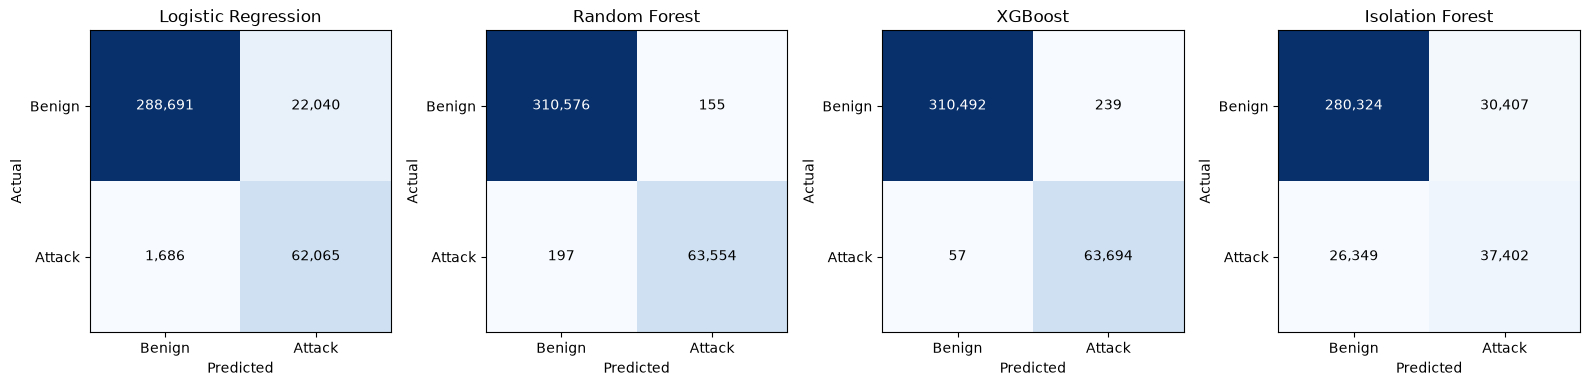

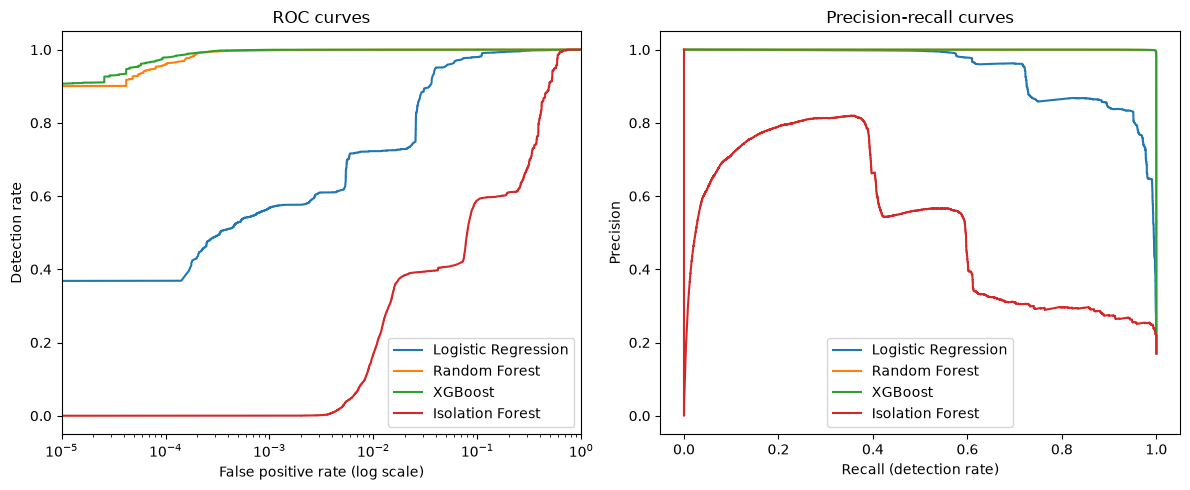

In [9]:
# Collect all four models' test results into one table
res = pd.DataFrame(results).set_index("model")
res.to_csv(f"{OUT_DIR}/02_model_comparison.csv")
cols = ["accuracy", "precision", "recall_detection_rate", "f1", "fpr", "fnr", "mcc", "pr_auc",
        "false_alarms_per_100k_benign", "fit_time_s"]
display(res[cols].round(4))

# Figure 1: one confusion matrix per model (counts of TN, FP, FN, TP)
fig, axes = plt.subplots(1, len(res), figsize=(4 * len(res), 3.8))
for ax, (name, row) in zip(np.atleast_1d(axes), res.iterrows()):
    cm = np.array([[row.TN, row.FP], [row.FN, row.TP]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j]):,}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Benign", "Attack"]); ax.set_yticks([0, 1], ["Benign", "Attack"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_confusion_matrices.png", dpi=200)
plt.show()

# Figure 2: ROC and precision-recall curves, which show performance at every threshold
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
for name, sc in test_scores.items():
    fpr_c, tpr_c, _ = roc_curve(y_test, sc)
    a1.plot(fpr_c, tpr_c, label=name)
    p_c, r_c, _ = precision_recall_curve(y_test, sc)
    a2.plot(r_c, p_c, label=name)
a1.set_xscale("log"); a1.set_xlim(1e-5, 1)
a1.set_xlabel("False positive rate (log scale)"); a1.set_ylabel("Detection rate"); a1.set_title("ROC curves")
a2.set_xlabel("Recall (detection rate)"); a2.set_ylabel("Precision"); a2.set_title("Precision-recall curves")
a1.legend(); a2.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_roc_pr_curves.png", dpi=200)
plt.show()

**What this shows** (`outputs/02_model_comparison.csv`, `02_confusion_matrices.png`, `02_roc_pr_curves.png`):

| Model | MCC | Detection rate | False positive rate | Missed attacks (FN) | False alarms (FP) |
|---|---|---|---|---|---|
| XGBoost | 0.9972 | 99.91% | 0.077% | 57 | 239 |
| Random Forest | 0.9967 | 99.69% | 0.050% | 197 | 155 |
| Logistic Regression | 0.8129 | 97.36% | 7.09% | 1,686 | 22,040 |
| Isolation Forest | 0.4771 | 58.67% | 9.79% | 26,349 | 30,407 |

XGBoost ranks first on MCC. The precision-recall curves show the same order, with the two tree models almost on top of each other.

## 10. Detection rate per attack type
An overall detection rate can hide weak performance on rare attacks. This table shows, for each original label in the test set, the share flagged as an attack. For BENIGN the value is the share wrongly flagged, i.e. the false positive rate.

In [10]:
# For each model, the share of each original label that raised an alert
per_label = {}
for name, sc in test_scores.items():
    flagged = sc >= thresholds_used[name]
    per_label[name] = pd.Series(flagged).groupby(labels_test).mean()
per_label = pd.DataFrame(per_label)
# Add the number of test flows per label, so small classes are visible
per_label.insert(0, "test_rows", pd.Series(labels_test).value_counts())
per_label = per_label.sort_values("test_rows", ascending=False)
per_label.to_csv(f"{OUT_DIR}/02_detection_rate_by_label.csv")
display(per_label.round(4))
print("Note: classes with very few test rows (e.g. Heartbleed, Infiltration, SQL injection) give unstable "
      "rates; one flow changes the result by a large amount.")

,test_rows,Logistic Regression,Random Forest,XGBoost,Isolation Forest
BENIGN,310731,0.0709,0.0005,0.0008,0.0979
DoS Hulk,25904,0.9874,0.9973,0.9998,0.8961
DDoS,19202,0.9992,0.9992,0.9998,0.6200
PortScan,13519,0.9900,0.9998,0.9999,0.0030
DoS GoldenEye,1542,0.9079,0.9987,1.0000,0.7263
FTP-Patator,890,0.6607,0.9978,1.0000,0.0000
DoS slowloris,806,0.8958,0.9975,0.9988,0.5732
DoS Slowhttptest,784,0.8776,0.9911,0.9987,0.8036
SSH-Patator,483,0.9027,0.9855,1.0000,0.0000
Bot,292,0.2705,0.7534,0.8733,0.0103


Note: classes with very few test rows (e.g. Heartbleed, Infiltration, SQL injection) give unstable rates; one flow changes the result by a large amount.


**What this shows** (`outputs/02_detection_rate_by_label.csv`): XGBoost detected at least 98% of every attack type with 220 or more test flows, except Botnet (87.3%; Random Forest 75.3%). Logistic Regression detected 0% of XSS and 0.45% of web brute force attacks, which suggests these are not linearly separable from normal web traffic. Isolation Forest caught 89.6% of DoS Hulk but only 0.3% of PortScan and 0% of FTP and SSH brute force. Infiltration (6 flows), SQL injection (3) and Heartbleed (2) are too small to judge.

## 11. Threshold trade-off (best supervised model)
A 0.5 threshold is a default, not a SOC decision. This table, built on the **validation** set, shows how detection and false alarms change with the threshold, so TeleComNet could choose a threshold that matches analyst capacity.

Best supervised model by MCC on the test set: XGBoost


,threshold,precision,recall_detection_rate,f1,fpr,fnr,false_alarms_per_100k_benign,FP,FN
0,0.05,0.99237,0.99980,0.99607,0.00158,0.00020,157.69267,490,13
1,0.10,0.99353,0.99970,0.99661,0.00134,0.00030,133.55603,415,19
2,0.20,0.99424,0.99962,0.99693,0.00119,0.00038,118.75223,369,24
3,0.30,0.99477,0.99951,0.99714,0.00108,0.00049,107.81029,335,31
4,0.40,0.99508,0.99937,0.99722,0.00101,0.00063,101.37386,315,40
5,0.50,0.99534,0.99923,0.99728,0.00096,0.00077,95.90289,298,49
6,0.60,0.99578,0.99911,0.99744,0.00087,0.00089,86.89188,270,57
7,0.70,0.99631,0.99865,0.99748,0.00076,0.00135,75.94994,236,86
8,0.80,0.99671,0.99805,0.99738,0.00068,0.00195,67.58257,210,124
9,0.90,0.99751,0.99744,0.99747,0.00051,0.00256,51.16966,159,163


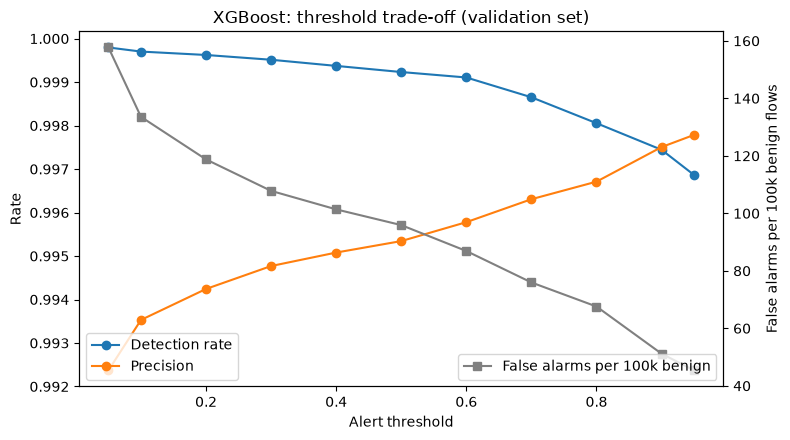

In [11]:
# Pick the best supervised model by test MCC (XGBoost in the full run)
sup = res.drop(index="Isolation Forest", errors="ignore")
best_name = sup["mcc"].idxmax()
best_model = {"Logistic Regression": logreg, "Random Forest": rf, "XGBoost": xgbm}[best_name]
print("Best supervised model by MCC on the test set:", best_name)

# Use the VALIDATION set here, so the threshold is not tuned on the test set
val_score = best_model.predict_proba(X_val)[:, 1]
rows = []
# Recompute the metrics at each candidate threshold
for t in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    r_ = evaluate(best_name, y_val, val_score, t, store=False)
    rows.append({k: r_[k] for k in ["threshold", "precision", "recall_detection_rate", "f1", "fpr", "fnr",
                                     "false_alarms_per_100k_benign", "FP", "FN"]})
thr = pd.DataFrame(rows)
thr.to_csv(f"{OUT_DIR}/02_threshold_tradeoff_validation.csv", index=False)
display(thr.round(5))

# Figure 3: detection rate, precision and false alarms as the threshold changes
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thr.threshold, thr.recall_detection_rate, marker="o", label="Detection rate")
ax.plot(thr.threshold, thr.precision, marker="o", label="Precision")
ax2 = ax.twinx()
ax2.plot(thr.threshold, thr.false_alarms_per_100k_benign, marker="s", color="grey", label="False alarms per 100k benign")
ax.set_xlabel("Alert threshold"); ax.set_ylabel("Rate"); ax2.set_ylabel("False alarms per 100k benign flows")
ax.set_title(f"{best_name}: threshold trade-off (validation set)")
ax.legend(loc="lower left"); ax2.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_threshold_tradeoff.png", dpi=200)
plt.show()

**What this shows** (`outputs/02_threshold_tradeoff_validation.csv`, `02_threshold_tradeoff.png`): on the validation set, lowering the threshold from 0.5 to 0.1 cut missed attacks from 49 to 19 for 117 extra false alarms (298 to 415). Raising it to 0.9 cut false alarms to 159 but more than tripled missed attacks to 163. The threshold should therefore be agreed with SOC managers, and the report recommends starting at around 0.1 to 0.2.

## 12. Explainability: which features drive the decisions?
Built-in importances from tree models can be biased towards features with many distinct values, so permutation importance (the drop in F1 when a feature is shuffled) is also computed for the best model on a sample of the test set.

,feature,rf_impurity,xgb_gain_share,permutation_XGBoost
50,Init_Win_bytes_forward,0.0386,0.0021,0.1210
47,Average Packet Size,0.0674,0.2068,0.0296
51,Init_Win_bytes_backward,0.0315,0.0046,0.0294
32,Bwd Header Length,0.0173,0.0836,0.0276
12,Bwd Packet Length Std,0.0650,0.4258,0.0189
23,Fwd IAT Min,0.0092,0.0024,0.0100
18,Flow IAT Min,0.0056,0.0004,0.0089
36,Max Packet Length,0.0411,0.0611,0.0057
8,Fwd Packet Length Std,0.0080,0.0035,0.0030
17,Flow IAT Max,0.0146,0.0002,0.0010


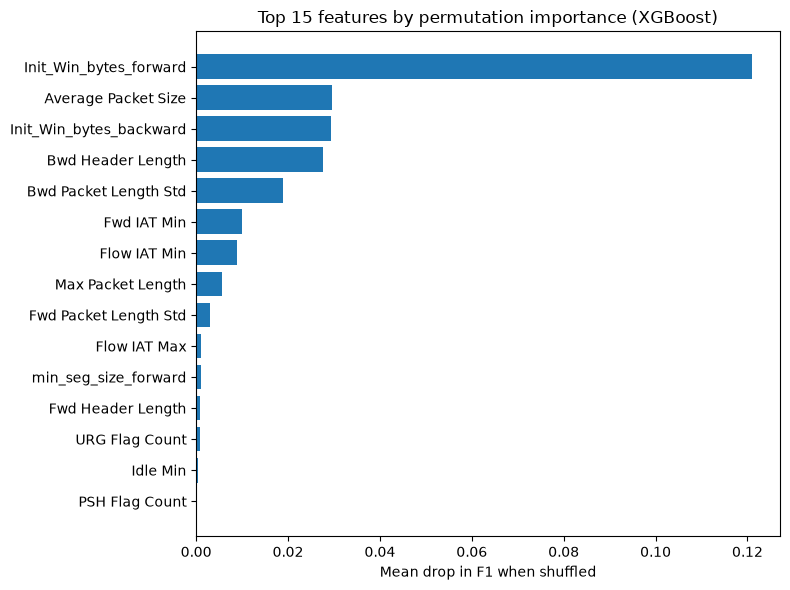

In [12]:
# Built-in importances from both tree models
imp = pd.DataFrame({"feature": feature_cols,
                    "rf_impurity": rf.feature_importances_,
                    "xgb_gain_share": xgbm.feature_importances_})

# Permutation importance on a 50,000-flow sample of the test set (to keep run time short)
n_perm = min(50_000, len(X_test))
rng = np.random.default_rng(RANDOM_STATE)
pi_idx = rng.choice(len(X_test), n_perm, replace=False)
# Shuffle one feature at a time and measure how much F1 drops
pi = permutation_importance(best_model, X_test[pi_idx], y_test[pi_idx], scoring="f1", n_repeats=3,
                            n_jobs=1, random_state=RANDOM_STATE)
imp[f"permutation_{best_name}"] = pi.importances_mean
imp = imp.sort_values(f"permutation_{best_name}", ascending=False)
imp.to_csv(f"{OUT_DIR}/02_feature_importance.csv", index=False)
display(imp.head(15).round(4))

# Figure 4: the 15 most important features by permutation importance
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.feature, top[f"permutation_{best_name}"])
ax.set_xlabel("Mean drop in F1 when shuffled")
ax.set_title(f"Top 15 features by permutation importance ({best_name})")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_feature_importance.png", dpi=200)
plt.show()

**What this shows** (`outputs/02_feature_importance.csv`, `02_feature_importance.png`): by permutation importance, XGBoost relies most on `Init_Win_bytes_forward`, the initial TCP window size (F1 drop 0.121, about four times the next feature, Average Packet Size at 0.030). The built-in measures disagree: XGBoost gain ranks `Bwd Packet Length Std` first, and Random Forest impurity ranks `Packet Length Std` first. Because the methods disagree, no single explanation should be shown to analysts as the truth. Heavy reliance on TCP window size may partly reflect the operating systems of the 2017 lab machines, which is flagged as a risk.

## 13. Experiment: does Destination Port act as a shortcut?
XGBoost is retrained with Destination Port added back, using the same number of trees. If performance rises noticeably, part of the gain may come from lab-specific port patterns rather than traffic behaviour, which supports excluding it.

In [13]:
if RUN_PORT_ABLATION and PORT_COL in df.columns:
    # Add Destination Port back as an extra column
    port = df[PORT_COL].to_numpy(dtype=np.float32)
    Xp_train = np.column_stack([X_train, port[idx_train]])
    Xp_test = np.column_stack([X_test, port[idx_test]])
    # Same settings and number of trees as the main XGBoost model, so only the port differs
    params = {**xgb_params, "n_estimators": best_n_trees}
    m_port = XGBClassifier(**params).fit(Xp_train, y_train, verbose=False)
    with_port = evaluate("XGBoost + Destination Port", y_test, m_port.predict_proba(Xp_test)[:, 1], 0.5, store=False)
    without = res.loc["XGBoost"].to_dict(); without["model"] = "XGBoost (no port)"
    ablation = pd.DataFrame([without, with_port]).set_index("model")[
        ["precision", "recall_detection_rate", "f1", "fpr", "fnr", "mcc"]]
    ablation.to_csv(f"{OUT_DIR}/02_port_ablation.csv")
    display(ablation.round(5))
    # Where Destination Port ranks among all features when it is included
    port_rank = pd.Series(m_port.feature_importances_, index=feature_cols + [PORT_COL]).rank(ascending=False)
    print(f"Destination Port importance rank when included: {int(port_rank[PORT_COL])} of {len(port_rank)}")
    del Xp_train, Xp_test

,precision,recall_detection_rate,f1,fpr,fnr,mcc
model,,,,,,
XGBoost (no port),0.99626,0.99911,0.99768,0.00077,0.00089,0.99721
XGBoost + Destination Port,0.99726,0.99922,0.99824,0.00056,0.00078,0.99788


Destination Port importance rank when included: 16 of 63


**What this shows** (`outputs/02_port_ablation.csv`): adding Destination Port back raised MCC only from 0.9972 to 0.9979 and lowered the false positive rate from 0.077% to 0.056%. The model does not need the port, so excluding it costs little while removing a lab-specific shortcut risk.

## 14. Experiment: detecting unseen (zero-day) attacks
**Why:** a supervised model only learns the attacks in its training data, so its near-perfect test scores say nothing about attacks it has never seen. This experiment tests that directly.

**Note on the term:** a true zero-day attack exploits a vulnerability that is not yet publicly known. Here, removing a whole attack family from training **simulates** that situation: the model meets an attack type for the first time at test time.

**What:** each attack family is removed from training in turn, XGBoost is retrained, and its detection rate on that family in the test set is measured. Isolation Forest is shown alongside: it never saw any attacks, so its figures come from the model in Section 8. This tests the claim that anomaly detection helps against unseen (zero-day) attacks. A chart of the results is drawn in the next cell.

In [14]:
if RUN_UNSEEN_ATTACKS:
    # Attack family of every flow, split the same way as the data
    fam_all = df["attack_family"].to_numpy()
    fam_train, fam_test = fam_all[idx_train], fam_all[idx_test]
    # Isolation Forest alerts from Section 8 (it never saw attacks, so no retraining is needed)
    iso_flag = test_scores["Isolation Forest"] >= thresholds_used["Isolation Forest"]
    xgb_flag_full = test_scores["XGBoost"] >= 0.5
    rows = []
    # Repeat for each attack family: remove it from training, retrain XGBoost, test on it
    for fam in [f for f in pd.Series(fam_test).value_counts().index if f != "Benign"]:
        if (fam_test == fam).sum() < 20:
            continue                      # too few test rows to give a meaningful rate
        # Training flows WITHOUT this family, so it is unseen (simulated zero-day)
        keep = fam_train != fam
        m = XGBClassifier(**{**xgb_params, "n_estimators": best_n_trees})
        m.fit(X_train[keep], y_train[keep], verbose=False)
        # Test flows of the held-out family only
        mask = fam_test == fam
        unseen_flag = m.predict_proba(X_test[mask])[:, 1] >= 0.5
        benign_mask = fam_test == "Benign"
        rows.append({"held_out_family": fam, "test_rows": int(mask.sum()),
                     "xgb_seen_detection": xgb_flag_full[mask].mean(),
                     "xgb_unseen_detection": unseen_flag.mean(),
                     "isolation_forest_detection": iso_flag[mask].mean(),
                     "xgb_unseen_benign_fpr": (m.predict_proba(X_test[benign_mask])[:, 1] >= 0.5).mean()})
        print(f"done: {fam}")
    unseen = pd.DataFrame(rows).set_index("held_out_family")
    unseen.to_csv(f"{OUT_DIR}/02_unseen_attack_experiment.csv")
    display(unseen.round(4))

done: DoS
done: DDoS
done: PortScan
done: Brute Force
done: Web Attack
done: Botnet


,test_rows,xgb_seen_detection,xgb_unseen_detection,isolation_forest_detection,xgb_unseen_benign_fpr
held_out_family,,,,,
DoS,29036,0.9998,0.1008,0.8756,0.0006
DDoS,19202,0.9998,0.6305,0.6200,0.0008
PortScan,13519,0.9999,0.0024,0.0030,0.0006
Brute Force,1373,1.0000,0.0022,0.0000,0.0008
Web Attack,321,0.9813,0.8318,0.0654,0.0007
Botnet,292,0.8733,0.0000,0.0103,0.0004


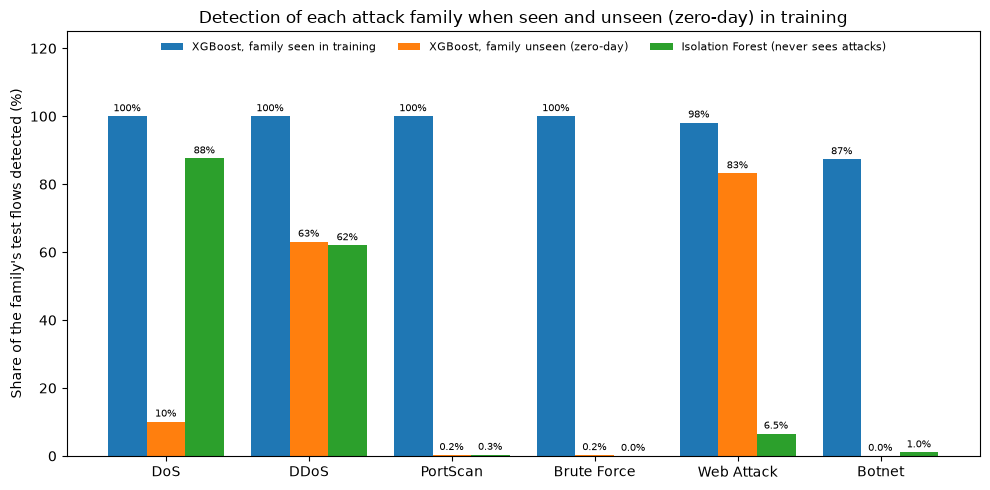

In [15]:
# Chart of the unseen (zero-day) experiment. It reads the CSV saved above, so it retrains nothing
# and can be re-run on its own after the setup cell (Section 1).
# Three bars per family: XGBoost when the family was in training, XGBoost when it was removed
# (simulated zero-day), and Isolation Forest, which never sees any attacks.
unseen_plot = pd.read_csv(f"{OUT_DIR}/02_unseen_attack_experiment.csv", index_col="held_out_family")
bars = {"XGBoost, family seen in training": "xgb_seen_detection",
        "XGBoost, family unseen (zero-day)": "xgb_unseen_detection",
        "Isolation Forest (never sees attacks)": "isolation_forest_detection"}
x = np.arange(len(unseen_plot))
width = 0.27
fig, ax = plt.subplots(figsize=(10, 5))
for i, (label, col) in enumerate(bars.items()):
    vals = unseen_plot[col].to_numpy() * 100
    pos = x + (i - 1) * width
    ax.bar(pos, vals, width, label=label)
    for xi, v in zip(pos, vals):
        ax.text(xi, v + 1.5, f"{v:.0f}%" if v >= 10 else f"{v:.1f}%", ha="center", fontsize=7)
ax.set_xticks(x, unseen_plot.index)
ax.set_ylabel("Share of the family's test flows detected (%)")
ax.set_ylim(0, 125)
ax.set_title("Detection of each attack family when seen and unseen (zero-day) in training")
ax.legend(loc="upper center", ncol=3, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_unseen_attack_chart.png", dpi=200)
plt.show()

**What this shows** (`outputs/02_unseen_attack_experiment.csv`, `02_unseen_attack_chart.png`):

| Family | XGBoost (seen) | XGBoost (unseen, zero-day) | Isolation Forest |
|---|---|---|---|
| DoS | 99.98% | 10.08% | 87.56% |
| DDoS | 99.98% | 63.05% | 62.00% |
| PortScan | 99.99% | 0.24% | 0.30% |
| Brute Force | 100% | 0.22% | 0% |
| Web Attack | 98.13% | 83.18% | 6.54% |
| Botnet | 87.33% | 0% | 1.03% |

This is the key finding. When an attack family is unseen (zero-day), XGBoost's detection collapses: to 10.1% for DoS and almost zero for PortScan, brute force and Botnet. Some knowledge carries over between related families (Web Attack 83.2%, DDoS 63.0%). Isolation Forest partly fills the gap for loud, high-volume attacks (87.6% of unseen DoS) but catches almost none of the stealthy ones, and its 9.8% false positive rate rules it out as the main detector. This supports using it as a secondary alert stream alongside XGBoost.

## 15. Extension: multi-class classification by attack family
A SOC needs to know not just whether a flow is malicious but what kind of attack it is, because the response differs. XGBoost is trained to predict the attack family, with balanced sample weights. Macro-averaged F1 is reported because it gives every family equal weight, however rare.

,precision,recall,f1-score,support
Benign,0.9999,0.9989,0.9994,310731.000
Botnet,0.5756,0.9384,0.7135,292.000
Brute Force,0.9978,1.0000,0.9989,1373.000
DDoS,0.9998,0.9998,0.9998,19202.000
DoS,0.9976,0.9998,0.9987,29036.000
Heartbleed,1.0000,1.0000,1.0000,2.000
Infiltration,1.0000,0.5000,0.6667,6.000
PortScan,0.9965,0.9996,0.9980,13519.000
Web Attack,0.9551,0.9938,0.9740,321.000
accuracy,0.9990,0.9990,0.9990,0.999


Macro F1: 0.9277 | fit time 138s


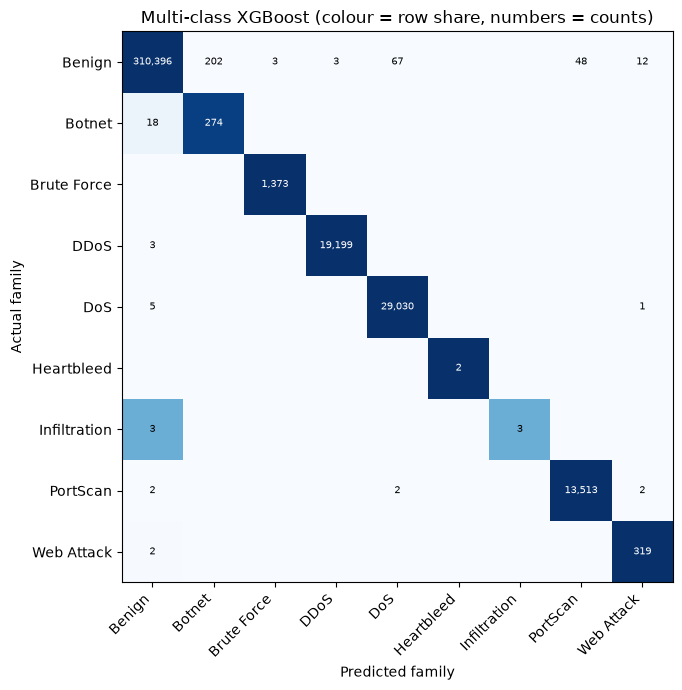

In [16]:
if RUN_MULTICLASS:
    # Turn family names into numbers 0..8 for the multi-class model
    fam_codes, fam_names = pd.factorize(df["attack_family"], sort=True)
    yf_train, yf_val, yf_test = fam_codes[idx_train], fam_codes[idx_val], fam_codes[idx_test]
    # Same type of model, now predicting one of 9 families instead of attack / benign
    mc = XGBClassifier(n_estimators=500, learning_rate=0.1, max_depth=8, subsample=0.8, colsample_bytree=0.8,
                       tree_method="hist", objective="multi:softprob", eval_metric="mlogloss",
                       early_stopping_rounds=30, n_jobs=N_JOBS, random_state=RANDOM_STATE)
    _, t_fit = timed(mc.fit, X_train, yf_train, sample_weight=compute_sample_weight("balanced", yf_train),
                     eval_set=[(X_val, yf_val)], verbose=False)
    # Predicted family for every test flow
    yf_pred = mc.predict(X_test)
    report = pd.DataFrame(classification_report(yf_test, yf_pred, labels=range(len(fam_names)),
                                                target_names=list(fam_names), output_dict=True,
                                                zero_division=0)).T
    report.to_csv(f"{OUT_DIR}/02_multiclass_report.csv")
    display(report.round(4))
    print(f"Macro F1: {report.loc['macro avg', 'f1-score']:.4f} | fit time {t_fit:.0f}s")

    # Multi-class confusion matrix, coloured by the share of each actual family
    cmf = confusion_matrix(yf_test, yf_pred, labels=range(len(fam_names)))
    cmn = cmf / cmf.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(fam_names)):
        for j in range(len(fam_names)):
            if cmf[i, j]:
                ax.text(j, i, f"{cmf[i, j]:,}", ha="center", va="center", fontsize=7,
                        color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(fam_names)), fam_names, rotation=45, ha="right")
    ax.set_yticks(range(len(fam_names)), fam_names)
    ax.set_xlabel("Predicted family"); ax.set_ylabel("Actual family")
    ax.set_title("Multi-class XGBoost (colour = row share, numbers = counts)")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/02_multiclass_confusion_matrix.png", dpi=200)
    plt.show()

**What this shows** (`outputs/02_multiclass_report.csv`, `02_multiclass_confusion_matrix.png`): predicting the attack family, XGBoost reached a macro F1 of 0.928. Most families scored above 0.97 F1. Botnet was the weakest (precision 0.576, recall 0.938): most bot flows were found, but about 4 in 10 flows predicted as Botnet were actually something else. Infiltration recall was 0.5 on only 6 test flows.

## 16. Sample predictions, saved models and run configuration
**What:** saves a few example flows of every type with each model's score, saves the best model and Isolation Forest, and records every setting and library version.

**Why:** the sample predictions are concrete testing evidence for the report appendix. The saved models can be reused in CW2. The configuration file lets anyone reproduce the run exactly.

In [17]:
# Sample predictions: a few test flows of each type, with every model's score and decision
rng = np.random.default_rng(RANDOM_STATE)
picks = []
for lbl in pd.unique(labels_test):
    pos = np.where(labels_test == lbl)[0]
    picks.extend(rng.choice(pos, min(3, len(pos)), replace=False))
picks = np.array(picks)
sample = pd.DataFrame({"true_label": labels_test[picks], "is_attack": y_test[picks]})
for name, sc in test_scores.items():
    sample[f"{name} score"] = sc[picks].round(4)
    sample[f"{name} alert"] = (sc[picks] >= thresholds_used[name]).astype(int)
sample.to_csv(f"{OUT_DIR}/02_sample_predictions.csv", index=False)
display(sample.head(20))

# Saved for reuse in CW2. The models folder is excluded from GitHub (.gitignore), because a
# Random Forest file can be hundreds of MB.
# Save the best model and Isolation Forest with their features and thresholds
joblib.dump({"model": best_model, "features": feature_cols, "threshold": 0.5}, f"{MODEL_DIR}/best_binary_model.joblib")
joblib.dump({"model": iso, "features": feature_cols, "threshold": iso_threshold}, f"{MODEL_DIR}/isolation_forest.joblib")

# Record every setting and library version so the run can be reproduced
with open(f"{OUT_DIR}/02_run_config.json", "w") as fh:
    json.dump({"rows": int(len(df)), "sample_frac": SAMPLE_FRAC, "n_features": len(feature_cols),
               "split": "stratified by Label, 70/15/15", "random_state": RANDOM_STATE,
               "logistic_regression": {"max_iter": 1000, "class_weight": "balanced", "scaling": "StandardScaler"},
               "random_forest": {"n_estimators": 100, "class_weight": "balanced_subsample"},
               "xgboost": {**{k: v for k, v in xgb_params.items() if k != "n_jobs"}, "best_n_trees": int(best_n_trees)},
               "isolation_forest": {"n_estimators": 200, "max_samples": 256, "trained_on": "benign training flows",
                                    "threshold": iso_threshold, "threshold_rule": "max F1 on validation"},
               "best_supervised_model": best_name,
               "versions": {"sklearn": sklearn.__version__, "xgboost": xgb.__version__, "pandas": pd.__version__}},
              fh, indent=2, default=float)
print("Saved models and outputs/02_run_config.json")

,true_label,is_attack,Logistic Regression score,Logistic Regression alert,Random Forest score,Random Forest alert,XGBoost score,XGBoost alert,Isolation Forest score,Isolation Forest alert
0,BENIGN,0,0.0149,0,0.0000,0,0.0000,0,0.4121,0
1,BENIGN,0,0.0001,0,0.0000,0,0.0000,0,0.3453,0
2,BENIGN,0,0.1904,0,0.0000,0,0.0000,0,0.3683,0
3,DoS Hulk,1,0.9997,1,1.0000,1,1.0000,1,0.6128,1
4,DoS Hulk,1,1.0000,1,1.0000,1,1.0000,1,0.6385,1
5,DoS Hulk,1,1.0000,1,1.0000,1,1.0000,1,0.5148,1
6,PortScan,1,0.8719,1,1.0000,1,1.0000,1,0.3813,0
7,PortScan,1,0.9039,1,0.9981,1,0.9980,1,0.3553,0
8,PortScan,1,0.9082,1,1.0000,1,0.9994,1,0.3344,0
9,DoS Slowhttptest,1,0.9209,1,1.0000,1,1.0000,1,0.6139,1


Saved models and outputs/02_run_config.json


## Summary of findings from Notebook 02
- **Best model:** XGBoost, with an MCC of 0.9972, a 99.91% detection rate and a 0.077% false positive rate (57 missed attacks and 239 false alarms in 374,482 test flows). Random Forest was close (MCC 0.9967) but missed 197 attacks (`02_model_comparison.csv`).
- **Baseline:** Logistic Regression's 93.7% accuracy hid 22,040 false alarms, showing why accuracy is misleading and why non-linear models are needed.
- **Rare and weak classes:** Botnet was the hardest common attack type (XGBoost 87.3%); the rarest classes are too small to judge (`02_detection_rate_by_label.csv`).
- **Threshold:** lowering it from 0.5 to 0.1 cut missed attacks from 49 to 19 for 117 extra false alarms on validation (`02_threshold_tradeoff_validation.csv`).
- **Destination Port:** including it changed MCC only from 0.9972 to 0.9979, so excluding it was cheap and safer (`02_port_ablation.csv`).
- **Unseen (zero-day) attacks:** detection collapsed when a family was missing from training (DoS 10.1%, PortScan 0.24%, Botnet 0%). Isolation Forest caught 87.6% of unseen DoS but almost none of the stealthy attacks (`02_unseen_attack_experiment.csv`, `02_unseen_attack_chart.png`).
- **Multi-class:** macro F1 of 0.928, with Botnet the weakest family (precision 0.576) (`02_multiclass_report.csv`).
- **Limitations:** CICIDS2017 is a 2017 lab dataset; random splits keep flows from the same attack session in both train and test; hyperparameters were set by reasoning, with only XGBoost's tree count tuned; robustness to adversarial evasion was not tested.